### Load and inspect the data

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

In [3]:
DATA_PATH = Path("../Data/Cleaned/Nepal_Online_Payment_System.csv")

df = pd.read_csv(DATA_PATH)

In [4]:
df.shape
df.head()

,period_end,bs_year,bs_month,fiscal_year_bs,instrument,category,txn_count,txn_amount_npr_million,avg_txn_value_npr,is_flagged,flag_reason
0,2023-07,2080,Asar,2079/80,RTGS,Interbank / large value,76307,2983930,39104276.15,False,NaN
1,2023-07,2080,Asar,2079/80,ATM Cash Withdrawal,Cash,11042117,86964,7875.66,False,NaN
2,2023-07,2080,Asar,2079/80,ECC (Cheque Clearing),Clearing,1336586,718755,537754.40,False,NaN
3,2023-07,2080,Asar,2079/80,IPS,Interbank / retail,1808046,323816,179097.21,False,NaN
4,2023-07,2080,Asar,2079/80,Faster Payment Systems,Instant payments,9783842,321519,32862.24,False,NaN


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 645 entries, 0 to 644
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   period_end              645 non-null    str    
 1   bs_year                 645 non-null    int64  
 2   bs_month                645 non-null    str    
 3   fiscal_year_bs          645 non-null    str    
 4   instrument              645 non-null    str    
 5   category                645 non-null    str    
 6   txn_count               645 non-null    int64  
 7   txn_amount_npr_million  645 non-null    int64  
 8   avg_txn_value_npr       645 non-null    float64
 9   is_flagged              645 non-null    bool   
 10  flag_reason             12 non-null     str    
dtypes: bool(1), float64(1), int64(3), str(6)
memory usage: 51.1 KB


In [6]:
df.isnull().sum()

period_end                  0
bs_year                     0
bs_month                    0
fiscal_year_bs              0
instrument                  0
category                    0
txn_count                   0
txn_amount_npr_million      0
avg_txn_value_npr           0
is_flagged                  0
flag_reason               633
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
pd.set_option("display.max_colwidth", None)

display(
    df[df["is_flagged"] == True][
        ["period_end", "instrument", "flag_reason"]
    ]
)

,period_end,instrument,flag_reason
61,2023-11,IPS,"Source revision: Kartik PDF reported amount 133,124; Mangsir PDF revised to 133,089 (revised value used)"
66,2023-11,Mobile Banking,"Source revision: Kartik PDF reported count 25,649,080 / amount 218,309; Mangsir PDF revised to 26,981,617 / 228,328 (revised value used)"
103,2024-02,IPS,IPS count spike (>=4M vs ~1-3M typical); likely bulk/institutional batches
175,2024-07,IPS,IPS count spike (>=4M vs ~1-3M typical); likely bulk/institutional batches
223,2024-10,IPS,IPS count spike (>=4M vs ~1-3M typical); likely bulk/institutional batches
376,2025-07,IPS,IPS count spike (>=4M vs ~1-3M typical); likely bulk/institutional batches
427,2025-10,IPS,IPS count spike (>=4M vs ~1-3M typical); likely bulk/institutional batches
478,2026-01,IPS,IPS count spike (>=4M vs ~1-3M typical); likely bulk/institutional batches
495,2026-02,IPS,IPS count spike (>=4M vs ~1-3M typical); likely bulk/institutional batches
580,2026-07,IPS,IPS count spike (>=4M vs ~1-3M typical); likely bulk/institutional batches


### Check the reporting period

In [9]:
df["period_end"] = pd.to_datetime(df["period_end"])

df["period_end"].dtype

dtype('<M8[us]')

In [10]:
print("First reporting month:", df["period_end"].min())
print("Last reporting month:", df["period_end"].max())

print("Total reporting months:", df["period_end"].nunique())

First reporting month: 2023-07-01 00:00:00
Last reporting month: 2026-10-01 00:00:00
Total reporting months: 40


In [11]:
available_months = sorted(df["period_end"].unique())

available_months

[Timestamp('2023-07-01 00:00:00'),
 Timestamp('2023-08-01 00:00:00'),
 Timestamp('2023-09-01 00:00:00'),
 Timestamp('2023-10-01 00:00:00'),
 Timestamp('2023-11-01 00:00:00'),
 Timestamp('2023-12-01 00:00:00'),
 Timestamp('2024-01-01 00:00:00'),
 Timestamp('2024-02-01 00:00:00'),
 Timestamp('2024-03-01 00:00:00'),
 Timestamp('2024-04-01 00:00:00'),
 Timestamp('2024-05-01 00:00:00'),
 Timestamp('2024-06-01 00:00:00'),
 Timestamp('2024-07-01 00:00:00'),
 Timestamp('2024-08-01 00:00:00'),
 Timestamp('2024-09-01 00:00:00'),
 Timestamp('2024-10-01 00:00:00'),
 Timestamp('2024-11-01 00:00:00'),
 Timestamp('2024-12-01 00:00:00'),
 Timestamp('2025-01-01 00:00:00'),
 Timestamp('2025-02-01 00:00:00'),
 Timestamp('2025-03-01 00:00:00'),
 Timestamp('2025-04-01 00:00:00'),
 Timestamp('2025-05-01 00:00:00'),
 Timestamp('2025-06-01 00:00:00'),
 Timestamp('2025-07-01 00:00:00'),
 Timestamp('2025-08-01 00:00:00'),
 Timestamp('2025-09-01 00:00:00'),
 Timestamp('2025-10-01 00:00:00'),
 Timestamp('2025-11-

In [12]:
# Missing Months

all_months = pd.date_range(
    start=df["period_end"].min(),
    end=df["period_end"].max(),
    freq="MS"
)

missing_months = all_months.difference(
    df["period_end"].drop_duplicates()
)

print("Missing months:", len(missing_months))
print(missing_months)

Missing months: 0
DatetimeIndex([], dtype='datetime64[us]', freq='MS')


In [13]:
# Months and instruments reported

monthly_coverage = (
    df.groupby("period_end")["instrument"]
    .nunique()
    .reset_index(name="instruments_reported")
)

monthly_coverage

,period_end,instruments_reported
0,2023-07-01,16
1,2023-08-01,14
2,2023-09-01,14
3,2023-10-01,14
4,2023-11-01,14
5,2023-12-01,14
6,2024-01-01,14
7,2024-02-01,14
8,2024-03-01,14
9,2024-04-01,14


In [14]:
monthly_coverage["instruments_reported"].value_counts().sort_index()

instruments_reported
14     9
15     2
16     4
17    25
Name: count, dtype: int64

In [15]:
# Instrument availability matrix
availability_matrix = (
    df.pivot_table(
        index="period_end",
        columns="instrument",
        values="txn_count",
        aggfunc="count"
    )
    .notna()
    .astype(int)
)

availability_matrix

instrument,ATM Cash Withdrawal,Branchless Banking,Credit Cards,Cross Border QR Acquiring,Debit Cards,E-Commerce (card-based),ECC (Cheque Clearing),Faster Payment Systems,IPS,Internet Banking,Mobile Banking,Other Retail Payments,Point of Sales (POS),Prepaid Cards,QR-Based Payments,RTGS,Wallet
period_end,,,,,,,,,,,,,,,,,
2023-07-01,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1
2023-08-01,1,1,1,0,1,1,1,0,1,1,1,0,1,1,1,1,1
2023-09-01,1,1,1,0,1,1,1,0,1,1,1,0,1,1,1,1,1
2023-10-01,1,1,1,0,1,1,1,0,1,1,1,0,1,1,1,1,1
2023-11-01,1,1,1,0,1,1,1,0,1,1,1,0,1,1,1,1,1
2023-12-01,1,1,1,0,1,1,1,0,1,1,1,0,1,1,1,1,1
2024-01-01,1,1,1,0,1,1,1,0,1,1,1,0,1,1,1,1,1
2024-02-01,1,1,1,0,1,1,1,0,1,1,1,0,1,1,1,1,1
2024-03-01,1,1,1,0,1,1,1,0,1,1,1,0,1,1,1,1,1


In [16]:
availability_matrix.sum().sort_values()

instrument
Cross Border QR Acquiring    25
Other Retail Payments        29
Faster Payment Systems       31
Branchless Banking           40
Credit Cards                 40
Debit Cards                  40
E-Commerce (card-based)      40
ATM Cash Withdrawal          40
ECC (Cheque Clearing)        40
IPS                          40
Internet Banking             40
Mobile Banking               40
Point of Sales (POS)         40
Prepaid Cards                40
QR-Based Payments            40
RTGS                         40
Wallet                       40
dtype: int64

In [17]:
# Missing instruments per month

missing_instruments = (
    availability_matrix
    .eq(0)
    .stack()
    .reset_index()
)

missing_instruments.columns = [
    "period_end",
    "instrument",
    "not_reported"
]

missing_instruments = missing_instruments[
    missing_instruments["not_reported"]
]

missing_instruments

,period_end,instrument,not_reported
3,2023-07-01,Cross Border QR Acquiring,True
20,2023-08-01,Cross Border QR Acquiring,True
24,2023-08-01,Faster Payment Systems,True
28,2023-08-01,Other Retail Payments,True
37,2023-09-01,Cross Border QR Acquiring,True
41,2023-09-01,Faster Payment Systems,True
45,2023-09-01,Other Retail Payments,True
54,2023-10-01,Cross Border QR Acquiring,True
58,2023-10-01,Faster Payment Systems,True
62,2023-10-01,Other Retail Payments,True


In [18]:
missing_instruments.groupby("instrument").size()

instrument
Cross Border QR Acquiring    15
Faster Payment Systems        9
Other Retail Payments        11
dtype: int64

In [19]:
df[
    [
        "txn_count",
        "txn_amount_npr_million",
        "avg_txn_value_npr"
    ]
].describe().round(2)

,txn_count,txn_amount_npr_million,avg_txn_value_npr
count,645.00,645.00,6.450000e+02
mean,10396360.61,524058.02,5.573146e+06
std,17016382.05,1671827.57,2.482609e+07
min,43906.00,139.00,9.027800e+02
25%,196326.00,1963.00,5.950520e+03
50%,1061098.00,70428.00,8.165860e+03
75%,11799175.00,373978.00,4.683477e+04
max,82605104.00,14792709.00,2.568722e+08


In [20]:
summary = df[
    [
        "txn_count",
        "txn_amount_npr_million",
        "avg_txn_value_npr"
    ]
].describe()

summary = summary.rename(columns={
    "txn_count": "Transaction Count",
    "txn_amount_npr_million": "Transaction Amount (NPR Million)",
    "avg_txn_value_npr": "Average Transaction Value (NPR)"
})

summary.style.format("{:,.2f}")

,Transaction Count,Transaction Amount (NPR Million),Average Transaction Value (NPR)
count,645.00,645.00,645.00
mean,"10,396,360.61","524,058.02","5,573,145.58"
std,"17,016,382.05","1,671,827.57","24,826,087.15"
min,"43,906.00",139.00,902.78
25%,"196,326.00","1,963.00","5,950.52"
50%,"1,061,098.00","70,428.00","8,165.86"
75%,"11,799,175.00","373,978.00","46,834.77"
max,"82,605,104.00","14,792,709.00","256,872,233.33"


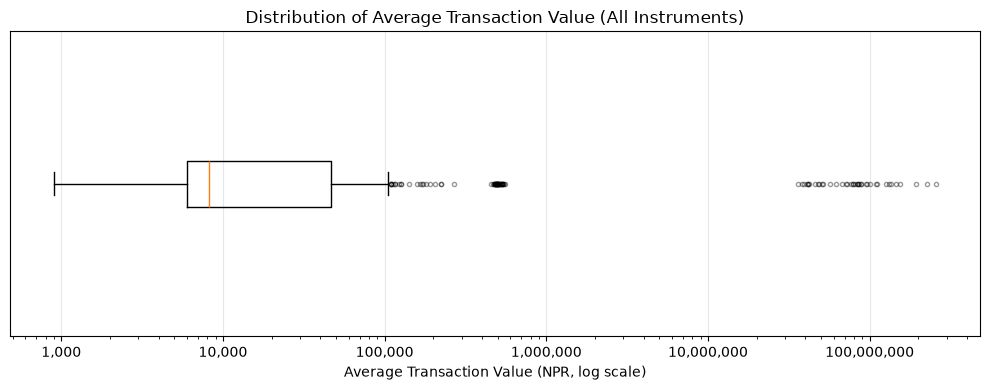

In [21]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

plt.figure(figsize=(10, 4))

plt.boxplot(
    df["avg_txn_value_npr"].dropna(),
    orientation="horizontal",   # replaces vert=False (deprecated in your matplotlib)
    flierprops=dict(marker="o", markersize=3, alpha=0.4),
)

plt.xscale("log")
plt.gca().xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:,.0f}"))
plt.xlabel("Average Transaction Value (NPR, log scale)")
plt.yticks([])                  # one box only, so the y tick is useless
plt.title("Distribution of Average Transaction Value (All Instruments)")
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

## Distribution of Average Transaction Value (log scale)

**What the code does**
- `plt.boxplot(..., orientation="horizontal")` draws a horizontal boxplot of `avg_txn_value_npr` for all instruments combined.
- `plt.xscale("log")` switches the x-axis to a log scale, so each tick is 10x the previous one.
- `FuncFormatter` shows tick labels as plain numbers (1,000 / 100,000) instead of powers of 10.
- Small, semi-transparent outlier dots and a light grid make the chart easier to read.
- `plt.yticks([])` removes the y-axis label, since there is only one box.

**Why log scale**
- On a linear axis, RTGS values (up to ≈ NPR 257M) stretched the scale and squashed the box near zero.
- On a log scale, the box (Q1 ≈ 5,951 to Q3 ≈ 46,835, median ≈ 8,166) is clearly visible.
- Equal distance on the chart means an equal **ratio**, not an equal difference.

**Observations**
- Most rows sit in a narrow band of roughly NPR 6K to 47K per transaction.
- Outlier dots on the right are the high-value instruments (RTGS, ECC, IPS), not data errors.
- Values span about 5 orders of magnitude (min ≈ 903, max ≈ 257M).

**Limitation:** All instruments are pooled, so this chart shows the overall spread but hides differences between instruments. See the per-instrument boxplot for that.

In [22]:
df.groupby("instrument")["avg_txn_value_npr"].agg(
    ["count", "median", "mean", "max"]
).sort_values("median", ascending=False).round(2)

,count,median,mean,max
instrument,,,,
RTGS,40,79964058.39,89056674.17,2.568722e+08
ECC (Cheque Clearing),40,498829.97,503570.26,5.582374e+05
IPS,40,109196.66,119016.13,2.670373e+05
Other Retail Payments,29,57859.20,57992.81,8.738566e+04
Internet Banking,40,45068.53,44265.57,5.498148e+04
Faster Payment Systems,31,29858.87,29577.92,3.286224e+04
Branchless Banking,40,22094.60,21972.68,2.409153e+04
Mobile Banking,40,8149.82,8146.25,9.127200e+03
ATM Cash Withdrawal,40,8141.64,8170.74,9.631270e+03


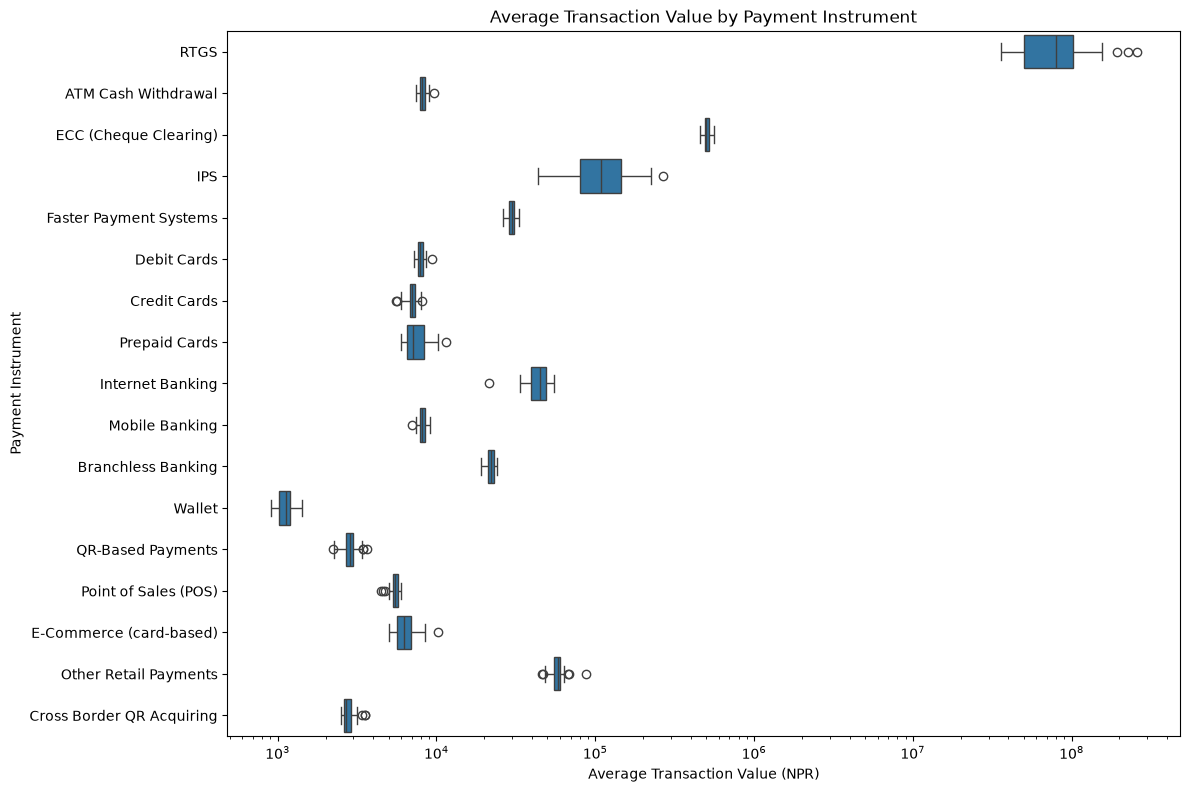

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 8))

sns.boxplot(
    data=df,
    x="avg_txn_value_npr",
    y="instrument"
)

plt.title("Average Transaction Value by Payment Instrument")
plt.xlabel("Average Transaction Value (NPR)")
plt.ylabel("Payment Instrument")
plt.ticklabel_format(style="plain", axis="x")
plt.tight_layout()
plt.xscale("log")
plt.show()

## Average Transaction Value by Payment Instrument

**What the chart shows:** A boxplot of `avg_txn_value_npr` for each instrument across the reporting months (Jul 2023 to Oct 2026).

**Key observations**
- **RTGS** has by far the largest transaction value (median ≈ NPR 80M, max ≈ 257M). It is used for large interbank transfers.
- **ECC (Cheque Clearing)** is next (median ≈ NPR 0.5M), followed by **IPS** (≈ 109K).
- Retail instruments (Mobile Banking, ATM, cards, POS, QR, Wallet) are small-ticket, roughly NPR 1K to 10K per transaction.
- **Wallet** has the lowest value (≈ NPR 1,100).

**Why a log scale is used**
- On a linear axis, RTGS stretched the scale and every other instrument collapsed into a thin line near zero.
- On a log scale, each tick is 10x the previous one (10³ = 1K, 10⁶ = 1M, 10⁸ = 100M), so all instruments are readable.
- Equal distance on the chart means an equal **ratio**, not an equal difference, so differences should not be judged by eye like on a normal axis.

**Notes**
- The outlier dots are months that fall outside 1.5x IQR of that instrument's own distribution.
- Some instruments have fewer data points (Cross Border QR: 25, Other Retail Payments: 29, Faster Payment Systems: 31 months) because they were not reported in every month. The rest have all 40.

In [24]:
# Which payment instruments contribute the most transaction value?
instrument_summary = (
    df.groupby("instrument")
    .agg(
        total_txn_count=("txn_count", "sum"),
        total_txn_amount_npr_million=("txn_amount_npr_million", "sum"),
        months_reported=("period_end", "nunique")
    )
)

instrument_summary["avg_monthly_amount_npr_million"] = (
    instrument_summary["total_txn_amount_npr_million"]
    / instrument_summary["months_reported"]
)

instrument_summary = instrument_summary.sort_values(
    "total_txn_amount_npr_million",
    ascending=False
)

display(instrument_summary.round(2))

,total_txn_count,total_txn_amount_npr_million,months_reported,avg_monthly_amount_npr_million
instrument,,,,
RTGS,2783377,246252108,40,6156302.70
ECC (Cheque Clearing),42092249,21247483,40,531187.07
Mobile Banking,2116458835,17164617,40,429115.42
Other Retail Payments,260870589,15001468,29,517292.00
Faster Payment Systems,508552965,14945907,31,482126.03
IPS,102756796,10065705,40,251642.62
QR-Based Payments,1318988912,3624587,40,90614.68
Debit Cards,445054115,3538414,40,88460.35
ATM Cash Withdrawal,417023998,3408591,40,85214.78


In [25]:
# Transaction amount contribution (%)
instrument_summary["amount_share_pct"] = (
    instrument_summary["total_txn_amount_npr_million"]
    / instrument_summary["total_txn_amount_npr_million"].sum()
) * 100

display(
    instrument_summary[
        [
            "total_txn_amount_npr_million",
            "amount_share_pct"
        ]
    ].round(2)
)

,total_txn_amount_npr_million,amount_share_pct
instrument,,
RTGS,246252108,72.85
ECC (Cheque Clearing),21247483,6.29
Mobile Banking,17164617,5.08
Other Retail Payments,15001468,4.44
Faster Payment Systems,14945907,4.42
IPS,10065705,2.98
QR-Based Payments,3624587,1.07
Debit Cards,3538414,1.05
ATM Cash Withdrawal,3408591,1.01


In [26]:
# Transaction count contribution (%)
instrument_summary["count_share_pct"] = (
    instrument_summary["total_txn_count"]
    / instrument_summary["total_txn_count"].sum()
) * 100

display(
    instrument_summary[
        ["total_txn_count", "count_share_pct"]
    ].sort_values(
        "count_share_pct",
        ascending=False
    ).round(2)
)

,total_txn_count,count_share_pct
instrument,,
Mobile Banking,2116458835,31.56
Wallet,1404815334,20.95
QR-Based Payments,1318988912,19.67
Faster Payment Systems,508552965,7.58
Debit Cards,445054115,6.64
ATM Cash Withdrawal,417023998,6.22
Other Retail Payments,260870589,3.89
IPS,102756796,1.53
ECC (Cheque Clearing),42092249,0.63


### Key Findings – Exploratory Data Analysis

1. RTGS accounts for 72.85% of the total transaction amount while contributing only 0.04% of transaction count.
2. Mobile Banking, Wallet and QR-Based Payments collectively account for 72.18% of transaction count.
3. Different payment instruments have significantly different average transaction values.
4. Reporting coverage varies across instruments, so cumulative totals should be interpreted with this limitation in mind.